# Market Lab — models

Supervised learning, unsupervised learning and forecasting on the cleaned data from `01_eda.ipynb`.
Everything here is computed by the same code the website's results come from (`market_lab/*.py`),
and every run is also recorded in MLflow (`mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
import sys; sys.path.insert(0, "..")
from market_lab import data, models, clusters, forecast
ds = data.load()
len(ds.model), data.FEATURES

(457,
 ['log_population',
  'log_income',
  'rent_to_income',
  'owner_rate',
  'vacancy_rate',
  'median_age',
  'housing_age'])

## 1. Regression: what explains a town's median home value?

Pipeline per model: impute (median + missing indicators) → standardize → model, all inside cross-validation.
Tunable models use **nested cross-validation** (inner grid search, outer 5-fold), so scores aren't optimistic.

In [2]:
reg = models.run_regression(ds.model)
reg.table.style.format({"rmse_log": "{:.3f}", "rmse_log_sd": "{:.3f}", "r2": "{:.3f}", "mae_dollars": "${:,.0f}", "median_abs_pct_error": "{:.1%}"})

,model,rmse_log,rmse_log_sd,r2,mae_dollars,median_abs_pct_error
0,Ridge regression,0.269,0.015,0.650,"$48,199",15.0%
1,Linear regression,0.269,0.015,0.650,"$48,188",15.2%
2,Random forest,0.280,0.026,0.626,"$51,548",16.7%
3,SVM (RBF kernel),0.284,0.023,0.606,"$49,045",14.4%
4,Decision tree,0.355,0.025,0.389,"$67,558",20.7%
5,Baseline (mean),0.466,0.036,-0.023,"$91,533",31.7%


Regularized linear models win: with ~450 towns and smooth relationships, trees and SVMs add variance without adding accuracy. The tuned hyper-parameters of the chosen model:

In [3]:
reg.best_name, reg.best_params

('Ridge regression', {'alpha': 1})

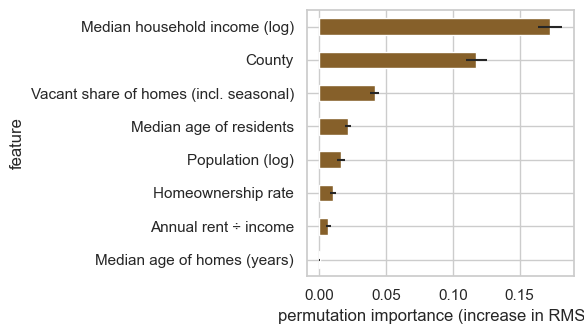

In [4]:
imp = reg.importance.assign(feature=lambda d: d.feature.map(lambda f: data.FEATURE_LABELS.get(f, "County")))
ax = imp.plot.barh(x="feature", y="importance", xerr="sd", legend=False, figsize=(6, 3.5), color="#86602a")
ax.invert_yaxis(); ax.set_xlabel("permutation importance (increase in RMSE)"); plt.tight_layout()

Out-of-fold predictions (each town predicted by a model that never saw it):

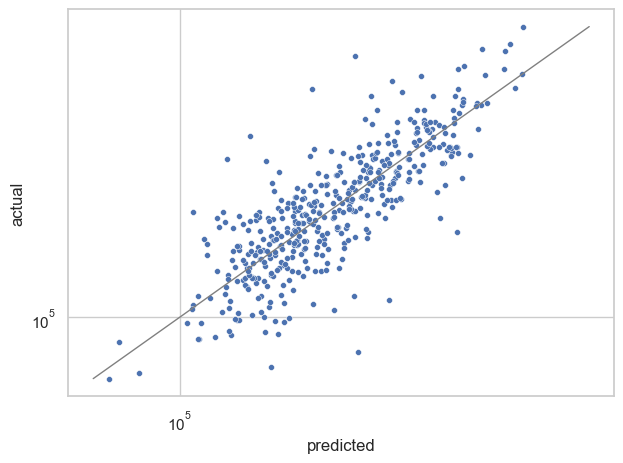

In [5]:
m = ds.model.assign(predicted=np.exp(reg.oof))
ax = sns.scatterplot(data=m, x="predicted", y="median_home_value", s=18)
lim = [m[["predicted", "median_home_value"]].min().min(), m[["predicted", "median_home_value"]].max().max()]
ax.plot(lim, lim, color="grey", lw=1); ax.set(xscale="log", yscale="log", xlabel="predicted", ylabel="actual"); plt.tight_layout()

## 2. Classification: is a town above the Maine median?
Logistic regression gives interpretable effects (odds ratio per standard deviation).

In [6]:
cls = models.run_classification(ds.model)
display(cls.table.style.format({"accuracy": "{:.3f}", "f1": "{:.3f}", "roc_auc": "{:.3f}", "roc_auc_sd": "{:.3f}"}))
cls.logistic_odds.assign(feature=lambda d: d.feature.map(data.FEATURE_LABELS)).round(2)

,model,accuracy,f1,roc_auc,roc_auc_sd
0,Random forest,0.856,0.851,0.934,0.027
1,Logistic regression,0.858,0.857,0.933,0.035
2,SVM (RBF kernel),0.851,0.847,0.927,0.027
3,Decision tree,0.766,0.752,0.818,0.052
4,Baseline (majority),0.501,0.000,0.500,0.000


,feature,odds_ratio_per_sd
0,Median household income (log),9.46
1,Population (log),3.34
2,Vacant share of homes (incl. seasonal),2.43
3,Annual rent ÷ income,1.89
4,Median age of residents,1.88
5,Median age of homes (years),0.93
6,Homeownership rate,0.77


## 3. Unsupervised: K-Means groups and a PCA map

In [7]:
cl = clusters.run(ds.towns)
pd.Series(cl.silhouettes, name="silhouette").to_frame().T.round(3)

,2,3,4,5,6,7,8
silhouette,0.175,0.175,0.183,0.158,0.162,0.151,0.157


In [8]:
display(pd.DataFrame({"name": cl.names, "towns": cl.towns.cluster.value_counts().sort_index()}))
cl.profiles.round(2).rename(index=cl.names)

,name,towns
0,Many seasonal homes · older residents,79
1,Lower home values · lower incomes,174
2,Higher incomes · larger towns,159
3,More renters · larger towns,59


,log_home_value,log_income,rent_to_income,owner_rate,vacancy_rate,median_age,housing_age,log_population
Many seasonal homes · older residents,0.80,0.28,0.33,0.37,1.44,1.02,0.29,-0.55
Lower home values · lower incomes,-0.81,-0.76,0.12,0.19,0.07,0.06,-0.02,-0.68
Higher incomes · larger towns,0.54,0.83,-0.42,0.27,-0.53,-0.41,-0.52,0.56
More renters · larger towns,-0.12,-0.37,0.34,-1.79,-0.71,-0.45,1.07,1.24


,pc1,pc2
log_home_value,0.35,0.38
log_income,0.45,0.46
rent_to_income,-0.11,-0.20
owner_rate,-0.19,0.56
vacancy_rate,-0.41,0.31
median_age,-0.36,0.19
housing_age,-0.09,-0.36
log_population,0.57,-0.16


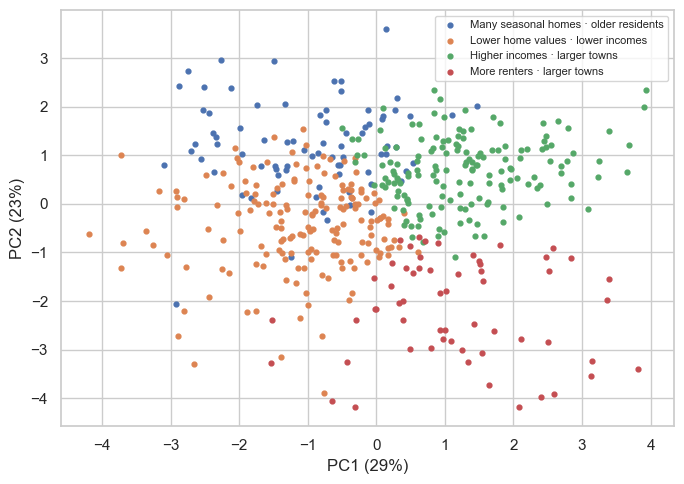

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
for c, name in cl.names.items():
    sel = cl.towns[cl.towns.cluster == c]; ax.scatter(sel.pc1, sel.pc2, s=12, label=name)
ax.set(xlabel=f"PC1 ({cl.explained[0]:.0%})", ylabel=f"PC2 ({cl.explained[1]:.0%})"); ax.legend(fontsize=8); plt.tight_layout()
cl.loadings.round(2)

Silhouette scores are low (~0.18): Maine towns form a continuum, so the groups are summaries rather than hard categories. Nearest neighbours are more useful for "towns like this one":

In [10]:
{t: [s["town"] for s in clusters.similar_towns(cl, t)] for t in ["Waterville", "Oakland", "Sidney"]}

{'Waterville': ['Lewiston', 'Bangor', 'Augusta', 'Old Town', 'Brewer'],
 'Oakland': ['Warren', 'Pittston', 'Vassalboro', 'Poland', 'Bucksport'],
 'Sidney': ['Carmel', 'Bowdoin', 'Levant', 'Berwick', 'Limerick']}

## 4. Forecasting the price index (rolling-origin backtest)

In [11]:
hpi = data.load_hpi()
outlooks = {g: forecast.outlook(hpi[g], g) for g in ["maine", "kennebec", "somerset"]}
pd.concat({g: (o.scores * 100).round(1) for g, o in outlooks.items()}, names=["area"]).rename(columns={1: "1-yr MAPE %", 2: "2-yr MAPE %"})

horizon                        1-yr MAPE %  2-yr MAPE %
area     model                                         
maine    AR(2)                         2.7          6.7
         Drift                         4.5          9.6
         Linear trend                  4.6          9.7
         Naive                         2.7          7.1
         Random forest (lags)          2.7          6.0
kennebec AR(2)                         2.4          5.4
         Drift                         4.3          8.5
         Linear trend                  4.4          8.6
         Naive                         2.8          7.2
         Random forest (lags)          2.8          6.2
somerset AR(2)                         3.9          8.6
         Drift                         4.8          9.3
         Linear trend                  5.1          9.5
         Naive                         3.3          7.2
         Random forest (lags)          3.6          7.4

In [12]:
pd.DataFrame([{"area": g, "model": o.best, **p} for g, o in outlooks.items() for p in o.projection])

,area,model,year,central,low,high
0,maine,Random forest (lags),2026,328.3,314.7,338.7
1,maine,Random forest (lags),2027,344.2,306.7,369.7
2,kennebec,AR(2),2026,312.3,300.8,319.8
3,kennebec,AR(2),2027,324.8,298.3,361.3
4,somerset,Naive,2026,353.9,331.3,367.9
5,somerset,Naive,2027,388.2,335.7,416.4


## Conclusions

- A tuned **ridge regression** predicts a town's median home value within about ±15% (median error), explaining ~65% of the variation.
- Random forests and SVMs don't beat it here; the extra flexibility isn't supported by ~450 data points.
- Classification above/below the median reaches ROC-AUC ≈ 0.93 (random forest ≈ logistic regression).
- Price-index forecasts: simple autoregressive models backtest at ~2.5–3.5% error one year ahead; uncertainty roughly doubles two years out.